# Load

In [16]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
df=pd.read_csv(r"C:\Users\YADVEER\OneDrive\Desktop\churn-analysis\data\telco_clean.csv")
print(df.shape,df['Churn'].mean().round(3))


(7043, 23) 0.265


# Build the segment

In [17]:
df["high_risk"]=(df['Contract']=="Month-to-month") & (df['tenure']<=12)
seg =df.groupby('high_risk').agg(
    customers = ('Churn' ,"size"),
    churners=('Churn',"sum"),
    churn_rate=('Churn',"mean"),
    monthly_rev=('MonthlyCharges' ,"sum")

)
seg["pct_of_customers"] = (seg.customers / seg.customers.sum() * 100).round(1)
seg["pct_of_churn"] = (seg.churners / seg.churners.sum() * 100).round(1)
print(seg)

           customers  churners  churn_rate  monthly_rev  pct_of_customers  \
high_risk                                                                   
False           5049       845    0.167360     340030.1              71.7   
True            1994      1024    0.513541     116086.5              28.3   

           pct_of_churn  
high_risk                
False              45.2  
True               54.8  


# Build the score

In [18]:
score = np.zeros(len(df))
score += np.where(df.Contract == "Month-to-month", 3, np.where(df.Contract == "One year", 1, 0))
score += np.where(df.tenure <= 12, 3, np.where(df.tenure <= 24, 1, 0))
score += np.where(df.InternetService == "Fiber optic", 2, 0)
score += np.where(df.PaymentMethod == "Electronic check", 2, 0)
score += np.where(df.TechSupport == "No", 1, 0)
score += np.where(df.OnlineSecurity == "No", 1, 0)
score += np.where(df.MonthlyCharges > df.MonthlyCharges.median(), 1, 0)
df["risk_score"] = score

# Check churn at each score

In [19]:
print(df.groupby("risk_score")['Churn'].agg(["size", "mean"]).round(3))

            size   mean
risk_score             
0.0          137  0.022
1.0          379  0.016
2.0          804  0.031
3.0          619  0.040
4.0          531  0.094
5.0          532  0.111
6.0          515  0.150
7.0          513  0.257
8.0         1008  0.309
9.0          350  0.397
10.0         669  0.541
11.0         358  0.651
12.0         175  0.589
13.0         453  0.759


# Create risk levels and validate

In [20]:
df['risk_level']=pd.cut(df['risk_score'],[-1,4,8,20],labels=['low','medium',"high"])
val=df.groupby("risk_level", observed=True)['Churn'].agg( customers="size",churn_rate='mean').round(3)
print(val)

            customers  churn_rate
risk_level                       
low              2470       0.044
medium           2568       0.225
high             2005       0.589


# Chart for the README

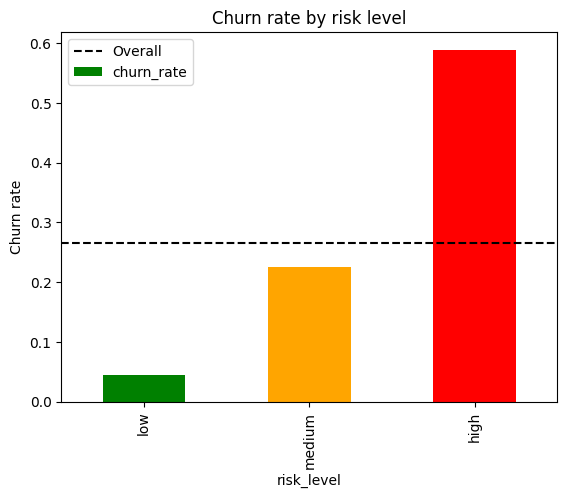

In [21]:
val["churn_rate"].plot(kind="bar",color=["green","orange","red"])
plt.axhline(df["Churn"].mean(), color="black", linestyle="--", label="Overall")
plt.title("Churn rate by risk level")
plt.ylabel("Churn rate")
plt.legend()
plt.savefig("../reports/churn_by_risk_level.png", bbox_inches="tight")
plt.show()


# Export for Power BI

In [22]:
df.to_csv("../data/telco_scored.csv", index=False)